# Liquid water: two rigid models at room temperature

Water molecules attract each other mainly through electrostatics: the hydrogens
carry positive charge and the oxygen negative charge. Here we compare two
classic rigid models at 300 K and 1 atm. **SPC/E** puts the three charges on the
atoms. **TIP4P/2005** moves the negative charge to a massless site M on the
H–O–H bisector.

Both start as randomly placed molecules in the same box. We measure the density
and the oxygen–oxygen radial distribution function, which shows the tetrahedral
hydrogen-bond network of liquid water. Units are LAMMPS `real` units: Å, fs,
K, atm, and kcal/mol for the whole box.

## 1. SPC/E

`Random` places 512 molecules in a 24.86 Å box (about 1 g/cm³), with at least
1.8 Å between atoms of different molecules. A short run with a 0.5 fs timestep
removes unfavourable random contacts; production then uses 2 fs at constant
pressure. Electrostatics use PPPM with relative force accuracy `kspace_accuracy`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fys2160_md import Random, RigidWater, MDSimulation

spce = RigidWater(oh_length=1.0, hoh_angle=109.47)
liquid = Random(N=512, box=24.86, molecule="water", bond=spce, min_distance=1.8, seed=11)
spce_sim = MDSimulation(
    liquid, units="real",
    epsilon={"O": 0.1553, "H": 0.0}, sigma={"O": 3.166, "H": 0.0}, lj_shift=False,
    charge={"O": -0.8476, "H": 0.4238}, coulomb="pppm", kspace_accuracy=1e-5,
    cutoff=10.0, coulomb_cutoff=10.0,
    ensemble="nvt", temperature=300, timestep=0.5, friction=0.005,
    pressure=1.0, pressure_time=1000.0,
)
spce_sim.run(steps=1000, thermo_every=100, trajectory_every=None, storage_name="spce-relax")
spce_run = spce_sim.run(steps=5000, ensemble="npt", timestep=2.0,
                        thermo_every=50, trajectory_every=250, storage_name="spce-liquid")

## 2. TIP4P/2005

The same protocol with TIP4P/2005 geometry and parameters. `m_distance` is the
O–M distance; as in LAMMPS, the charge given for O sits on M.

In [2]:
tip4p = RigidWater(oh_length=0.9572, hoh_angle=104.52, m_distance=0.1546)
liquid = Random(N=512, box=24.86, molecule="water", bond=tip4p, min_distance=1.8, seed=11)
tip4p_sim = MDSimulation(
    liquid, units="real",
    epsilon={"O": 0.1852, "H": 0.0}, sigma={"O": 3.1589, "H": 0.0}, lj_shift=False,
    charge={"O": -1.1128, "H": 0.5564}, coulomb="pppm", kspace_accuracy=1e-5,
    cutoff=10.0, coulomb_cutoff=10.0,
    ensemble="nvt", temperature=300, timestep=0.5, friction=0.005,
    pressure=1.0, pressure_time=1000.0,
)
tip4p_sim.run(steps=1000, thermo_every=100, trajectory_every=None, storage_name="tip4p-relax")
tip4p_run = tip4p_sim.run(steps=5000, ensemble="npt", timestep=2.0,
                          thermo_every=50, trajectory_every=250, storage_name="tip4p-liquid")

## 3. Density

The box adjusts to the target pressure. Averages use the second half of each
10 ps run; such short runs give about two significant digits.

SPC/E       density 0.992 g/cm³, temperature 299.0 K
TIP4P/2005  density 0.984 g/cm³, temperature 298.9 K


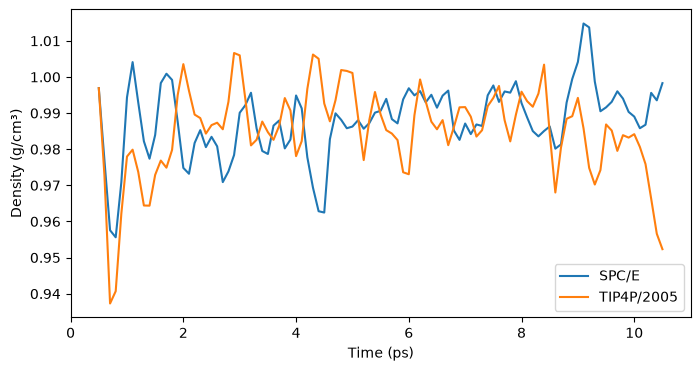

In [3]:
plt.figure(figsize=(8, 4))
for label, run in [("SPC/E", spce_run), ("TIP4P/2005", tip4p_run)]:
    data = run.thermo
    plt.plot(data.time/1000, data.mass_density, label=label)
    print(f"{label:11s} density {data.mass_density[len(data)//2:].mean():.3f} g/cm³,",
          f"temperature {data.temperature[len(data)//2:].mean():.1f} K")
plt.xlabel("Time (ps)")
plt.ylabel("Density (g/cm³)")
plt.legend()
plt.show()

## 4. Oxygen–oxygen radial distribution function

g(r) counts oxygen pairs at distance r relative to an ideal gas of the same
density. The first peak near 2.8 Å is the hydrogen-bonded neighbour shell; the
second near 4.5 Å reflects the tetrahedral network (4.5 ≈ 2.8 × 1.63).

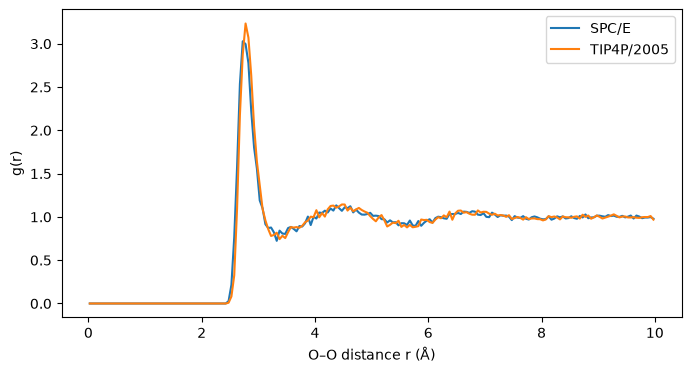

In [4]:
edges = np.linspace(0.0, 10.0, 201)
r = 0.5*(edges[1:] + edges[:-1])
plt.figure(figsize=(8, 4))
for label, run in [("SPC/E", spce_run), ("TIP4P/2005", tip4p_run)]:
    counts = np.zeros(len(r))
    frames = list(run.iter_frames())[10:]
    for frame in frames:
        oxygen, box = frame["positions"][::3], frame["box"]
        dr = oxygen[:, None, :] - oxygen[None, :, :]
        dr -= box*np.rint(dr/box)
        distance = np.linalg.norm(dr, axis=2)[np.triu_indices(len(oxygen), 1)]
        shell = 4/3*np.pi*(edges[1:]**3 - edges[:-1]**3)
        counts += np.histogram(distance, edges)[0] / (shell * len(oxygen)**2 / (2*np.prod(box)))
    plt.plot(r, counts/len(frames), label=label)
plt.xlabel("O–O distance r (Å)")
plt.ylabel("g(r)")
plt.legend()
plt.show()

## 5. Watch the liquid

Oxygen is red and hydrogen white. Drag to rotate and use the slider to step
through the production run.

In [5]:
tip4p_run.view()

Published densities at 298 K and 1 atm are about 0.998 g/cm³ for SPC/E and
0.997 g/cm³ for TIP4P/2005, obtained with long-range corrections to the
Lennard-Jones tail. This example truncates Lennard-Jones at 10 Å without that
correction and uses short runs, so its numbers are expected to be close but not
identical.